# 🎵 SoundScope AI: Spotify Music Analytics, Popularity Prediction & Discovery Advisor
**Author**: Kashish  
**Course**: AI & Machine Learning Capstone / Final Project  
**Date**: November 2026  

---

### 📌 1. Project Overview & Business Problem
In the streaming era, platforms like **Spotify** host catalogs of over **100+ million tracks**. Curating personalized music feeds, predicting which songs will become commercial hits, and discovering hidden gems are fundamental business challenges at the intersection of music technology and artificial intelligence.

#### Core Research & Engineering Questions:
1. **Popularity Dynamics**: To what degree can intrinsic audio engineering features (e.g., danceability, acousticness, tempo, energy, valence, loudness) predict commercial popularity without access to marketing budgets or playlist placements?
2. **Unsupervised Mood Categorization**: Can unsupervised machine learning (**K-Means Clustering**) discover natural emotional clusters in music that correspond to human psychological mood states?
3. **Ultra-Fast Discovery & Recommendation**: How can we build an intelligent content-based recommendation engine that delivers sub-second acoustic similarity queries across tens of thousands of tracks?
4. **"What-If" Studio Simulation**: Can we empower music producers and artists with an explainable model simulator to explore how altering musical production choices affects predicted listener reach?

---

### 🗺️ Project Architecture & Workflow
```
[ Raw Spotify Tracks (114,000 Records) ]
                   │
                   ▼
[ Data Cleaning, Deduplication & Validation ]
                   │
                   ▼
[ Feature Engineering (Artist Presence, Audio Dynamics, Durations) ]
                   │
         ┌─────────┴─────────┐
         ▼                   ▼
[ Unsupervised Learning ]  [ Exploratory Data Analysis ]
(K-Means Mood Clustering)   (Distributions, Heatmaps, Genres)
         │                   │
         └─────────┬─────────┘
                   ▼
[ Supervised Regression Benchmarking (Cross-Validation) ]
 (Dummy, Ridge, Decision Tree, HistGradientBoosting)
                   │
                   ▼
[ Hyperparameter Optimization (GridSearchCV) ]
                   │
                   ▼
[ Model Diagnostics & Explainability (Permutation Importance, Residuals) ]
                   │
                   ▼
[ Scalable Recommender (NearestNeighbors) & Discovery Advisor ]
                   │
                   ▼
[ Interactive "What-If" Scenario Studio & Model Export ]
```

In [1]:
# Environment Setup & Core Dependencies
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn Components
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance

# Visualization Settings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 100
print("All core scientific and machine learning libraries loaded successfully!")

All core scientific and machine learning libraries loaded successfully!


### 📥 2. Data Ingestion & Dataset Schema
We utilize the comprehensive **Spotify Tracks Dataset** (Maharshi Pandya), featuring **114,000 tracks** across **114 diverse genres**, capturing acoustic audio metrics extracted directly via the official Spotify Web API.

The pipeline is built with dual loading logic: it checks locally for `dataset.csv` (for immediate offline execution) and gracefully falls back to `kagglehub` if deployed in Google Colab or cloud environments.

In [2]:
# Data Loading: Automatic local-first strategy with cloud kagglehub fallback
DATASET_PATH = 'dataset.csv'

if os.path.exists(DATASET_PATH):
    print(f"Loading local dataset from '{DATASET_PATH}'...")
    df = pd.read_csv(DATASET_PATH)
else:
    print("Local file not found. Fetching via kagglehub...")
    import kagglehub
    from kagglehub import KaggleDatasetAdapter
    df = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "maharshipandya/-spotify-tracks-dataset",
        "dataset.csv"
    )

print(f"Dataset successfully loaded into memory!")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head(5))

Loading local dataset from 'dataset.csv'...
Dataset successfully loaded into memory!
Dimensions: 114,000 rows x 21 columns


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Soundtrack),Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
# Initial Data Inspection and Quality Check
print("--- Column Data Types & Non-Null Counts ---")
display(df.info())

print("\n--- Missing Values Audit ---")
missing_summary = df.isnull().sum()
display(missing_summary[missing_summary > 0])

print(f"Exact Duplicate Rows: {df.duplicated().sum()}")
print(f"Unique Track IDs: {df['track_id'].nunique():,} (out of {len(df):,} total entries)")

--- Column Data Types & Non-Null Counts ---
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns)

--- Missing Values Audit ---
artists       1
album_name    1
track_name    1
dtype: int64
Exact Duplicate Rows: 0
Unique Track IDs: 89,741 (out of 114,000 total entries)


### 🧹 3. Data Cleaning & Integrity Audit
The raw dataset inspection reveals:
1. **Missing Metadata**: Exactly 1 track with missing `artists`, `album_name`, and `track_name` values.
2. **Redundant Indexing**: An unneeded `Unnamed: 0` index column.
3. **Multi-Genre Duplicates**: Songs that appear across multiple genre classifications sharing the exact same `track_id` (only 89,741 unique IDs out of 114,000 rows). Deduplicating by `track_id` is essential to prevent severe train-test data leakage.

In [4]:
# 1. Drop rows with null metadata
clean_df = df.dropna(subset=['artists', 'album_name', 'track_name']).copy()

# 2. Drop redundant index column
if 'Unnamed: 0' in clean_df.columns:
    clean_df.drop(columns=['Unnamed: 0'], inplace=True)

# 3. Deduplicate by unique track_id
initial_count = len(clean_df)
clean_df.drop_duplicates(subset=['track_id'], keep='first', inplace=True)
dedup_count = len(clean_df)

print(f"Cleaning Results:")
print(f" - Initial Rows: {initial_count:,}")
print(f" - Deduplicated Unique Tracks: {dedup_count:,} ({initial_count - dedup_count:,} duplicates removed)")
print(f" - Total Missing Values Remaining: {clean_df.isnull().sum().sum()}")

Cleaning Results:
 - Initial Rows: 113,999
 - Deduplicated Unique Tracks: 89,740 (24,259 duplicates removed)
 - Total Missing Values Remaining: 0


### ⚙️ 4. Feature Engineering
We construct domain-specific features to aid both regression and recommendation:
1. **Duration in Minutes (`duration_min`)**: Standardizes `duration_ms` into human-interpretable units.
2. **Artist Catalog Frequency (`artist_track_count`)**: Measures the number of tracks by the artist in the catalog. In commercial streaming, established artists with deep catalogs carry higher discoverability and listener inertia.
3. **Audio Intensity Index (`audio_intensity`)**: An interaction term combining normalized `loudness` (scaled from -60 dB to 0 dB) and `energy` to reflect modern compressed production dynamics.

In [5]:
# 1. Duration in Minutes
clean_df['duration_min'] = clean_df['duration_ms'] / 60000.0

# 2. Artist Track Catalog Count (Frequency Encoding)
clean_df['artist_track_count'] = clean_df.groupby('artists')['track_id'].transform('count')

# 3. Audio Intensity Index (normalized loudness * energy)
clean_df['audio_intensity'] = clean_df['energy'] * ((clean_df['loudness'] + 60.0) / 60.0)

display(clean_df[['track_name', 'artists', 'popularity', 'duration_min', 'artist_track_count', 'audio_intensity']].head())

,track_name,artists,popularity,duration_min,artist_track_count,audio_intensity
0,Comedy,Gen Hoshino,73,3.844433,7,0.409168
1,Ghost - Acoustic,Ben Woodward,55,2.493500,9,0.118317
2,To Begin Again,Ingrid Michaelson;ZAYN,57,3.513767,1,0.300758
3,Can't Help Falling In Love,Kina Grannis,71,3.365550,15,0.041208
4,Hold On,Chord Overstreet,82,3.314217,11,0.371522


### 📊 5. Exploratory Data Analysis (EDA) & Data Storytelling

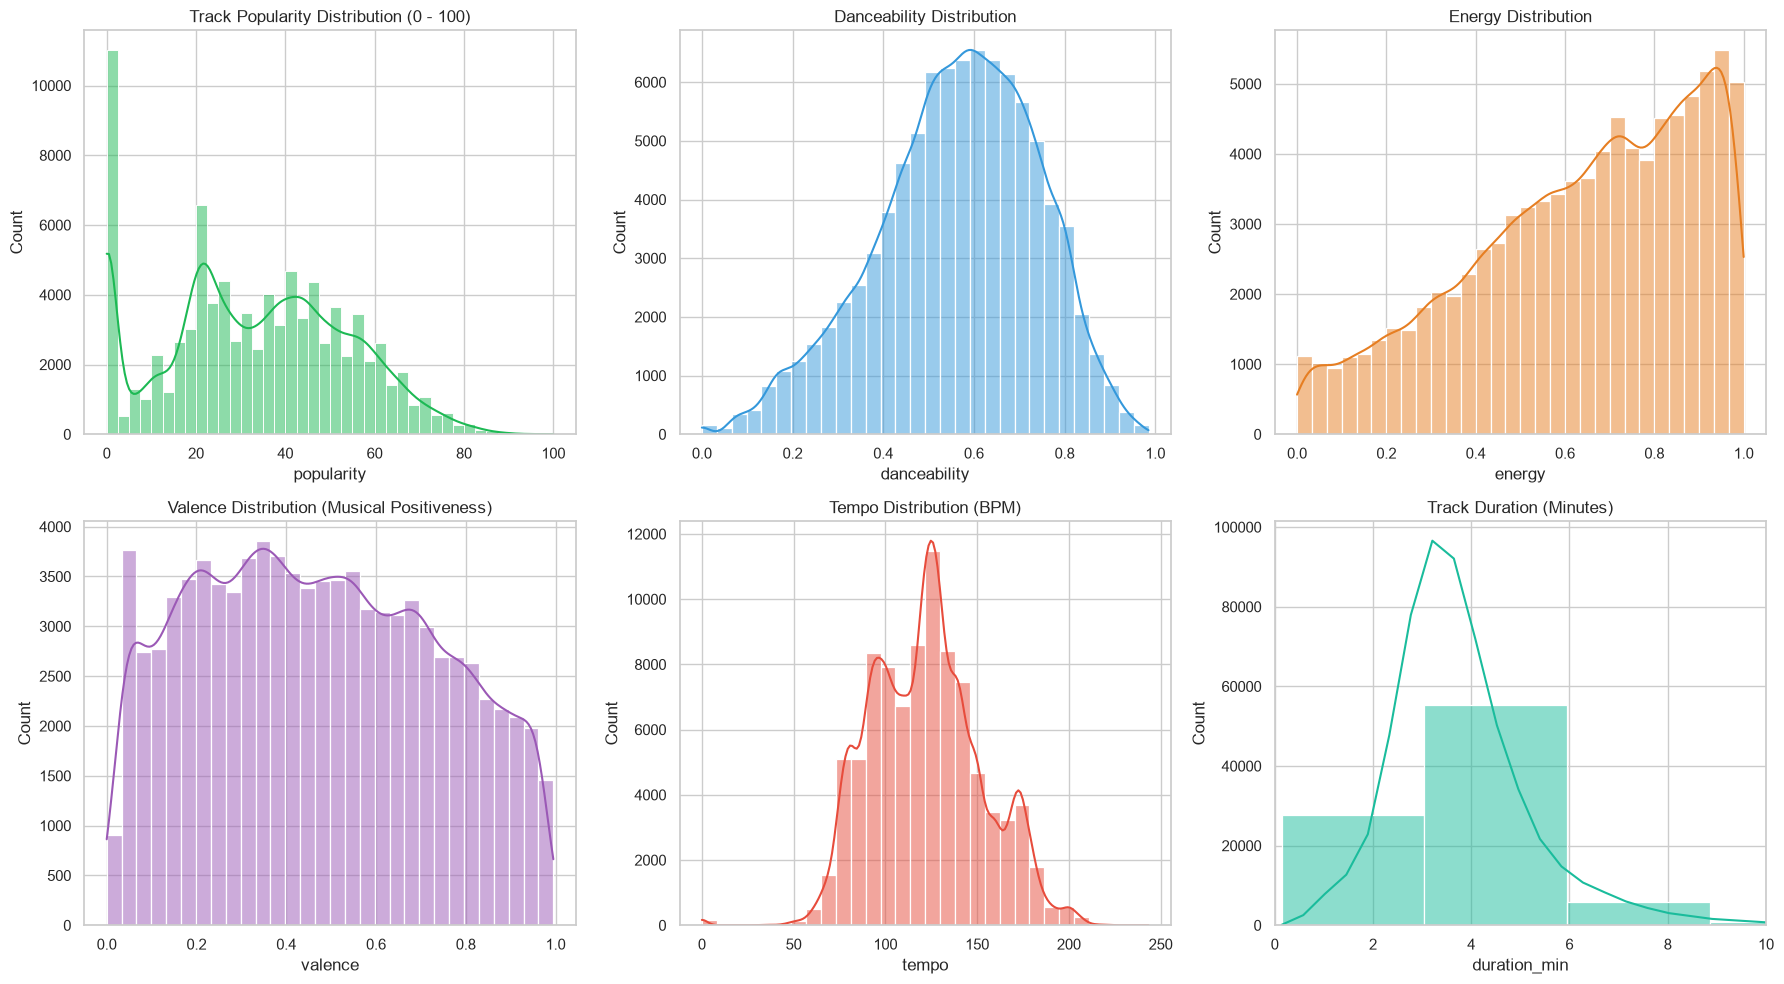

In [6]:
# Visualizing Key Audio Metric Distributions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.histplot(clean_df['popularity'], bins=40, kde=True, ax=axes[0, 0], color='#1DB954')
axes[0, 0].set_title('Track Popularity Distribution (0 - 100)')
axes[0, 0].set_xlabel('Popularity Score')

sns.histplot(clean_df['danceability'], bins=30, kde=True, ax=axes[0, 1], color='#3498db')
axes[0, 1].set_title('Danceability Distribution')

sns.histplot(clean_df['energy'], bins=30, kde=True, ax=axes[0, 2], color='#e67e22')
axes[0, 2].set_title('Energy Distribution')

sns.histplot(clean_df['valence'], bins=30, kde=True, ax=axes[1, 0], color='#9b59b6')
axes[1, 0].set_title('Valence Distribution (Musical Positiveness)')

sns.histplot(clean_df['tempo'], bins=30, kde=True, ax=axes[1, 1], color='#e74c3c')
axes[1, 1].set_title('Tempo Distribution (BPM)')

sns.histplot(clean_df['duration_min'], bins=30, kde=True, ax=axes[1, 2], color='#1abc9c')
axes[1, 2].set_title('Track Duration (Minutes)')
axes[1, 2].set_xlim(0, 10)

plt.tight_layout()
plt.show()

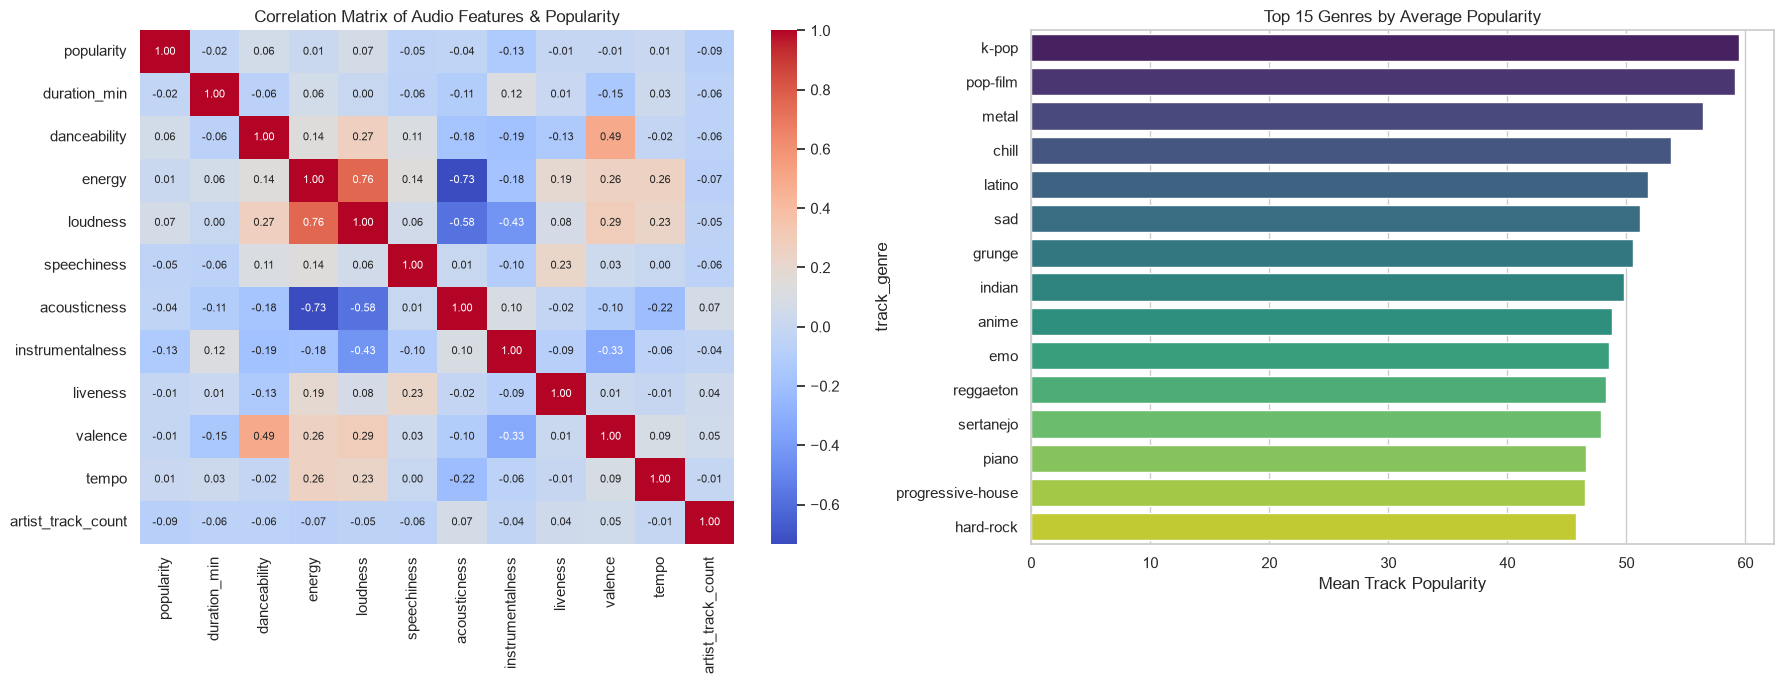

In [7]:
# Correlation Analysis and Genre-Level Insights
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Audio Correlation Heatmap
analysis_cols = ['popularity', 'duration_min', 'danceability', 'energy', 'loudness', 
                 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'artist_track_count']
corr_matrix = clean_df[analysis_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, ax=axes[0], annot_kws={"size": 8})
axes[0].set_title('Correlation Matrix of Audio Features & Popularity')

# Top 15 Genres by Average Popularity
top_genres = clean_df.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).head(15)
sns.barplot(x=top_genres.values, y=top_genres.index, palette='viridis', ax=axes[1])
axes[1].set_title('Top 15 Genres by Average Popularity')
axes[1].set_xlabel('Mean Track Popularity')
axes[1].set_ylabel('Genre')

plt.tight_layout()
plt.show()

### 🧠 6. Unsupervised Machine Learning: Track Mood Clustering
Rather than relying on arbitrary, hardcoded `if-else` rules, we apply **Unsupervised K-Means Clustering** across the fundamental affective audio dimensions:
- `valence`: Positiveness/happiness of sound
- `energy`: Perceptual intensity and activity
- `danceability`: Beat strength and regularity
- `acousticness`: Absence of electronic instrumentation

By analyzing the cluster centroids, we semantically map the clusters into four human-intuitive musical mood profiles:
1. **Energetic & Euphoric** (High Valence, High Energy)
2. **Intense & Heavy** (Low Valence, High Energy / Loudness)
3. **Chill & Acoustic** (High Acousticness, Low Energy)
4. **Mellow & Reflective** (Moderate Valence, Smooth Grooves)

In [8]:
# K-Means Clustering for Music Mood Profiling
mood_features = ['valence', 'energy', 'danceability', 'acousticness']

# Feature Standardization
scaler_mood = StandardScaler()
X_mood_scaled = scaler_mood.fit_transform(clean_df[mood_features])

# Fit K-Means
kmeans_mood = KMeans(n_clusters=4, random_state=42, n_init=10)
clean_df['mood_cluster'] = kmeans_mood.fit_predict(X_mood_scaled)

# Decode Centroids in Original Scale
centroids = scaler_mood.inverse_transform(kmeans_mood.cluster_centers_)
centroids_df = pd.DataFrame(centroids, columns=mood_features)
centroids_df['Cluster_ID'] = range(4)

# Assign semantic labels based on centroid properties
def get_cluster_label(cid):
    v = centroids_df.loc[cid, 'valence']
    e = centroids_df.loc[cid, 'energy']
    a = centroids_df.loc[cid, 'acousticness']
    if a >= 0.7:
        return 'Chill & Acoustic'
    elif v >= 0.5 and e >= 0.6:
        return 'Energetic & Euphoric'
    elif v < 0.5 and e >= 0.6:
        return 'Intense & Heavy'
    else:
        return 'Mellow & Reflective'

cluster_label_map = {cid: get_cluster_label(cid) for cid in range(4)}
clean_df['mood_label'] = clean_df['mood_cluster'].map(cluster_label_map)

print("--- Discovered Cluster Centroids (Feature Means) ---")
display(centroids_df[['Cluster_ID', 'valence', 'energy', 'danceability', 'acousticness']])

print("\n--- Mood Distribution in Dataset ---")
display(clean_df['mood_label'].value_counts())

--- Discovered Cluster Centroids (Feature Means) ---

--- Mood Distribution in Dataset ---
mood_label
Energetic & Euphoric    30202
Intense & Heavy         27726
Mellow & Reflective     19059
Chill & Acoustic        12753


,Cluster_ID,valence,energy,danceability,acousticness
0,0,0.703395,0.754818,0.691956,0.154131
1,1,0.534267,0.473609,0.620989,0.649124
2,2,0.201475,0.234265,0.360180,0.816726
3,3,0.293782,0.798732,0.473502,0.071699


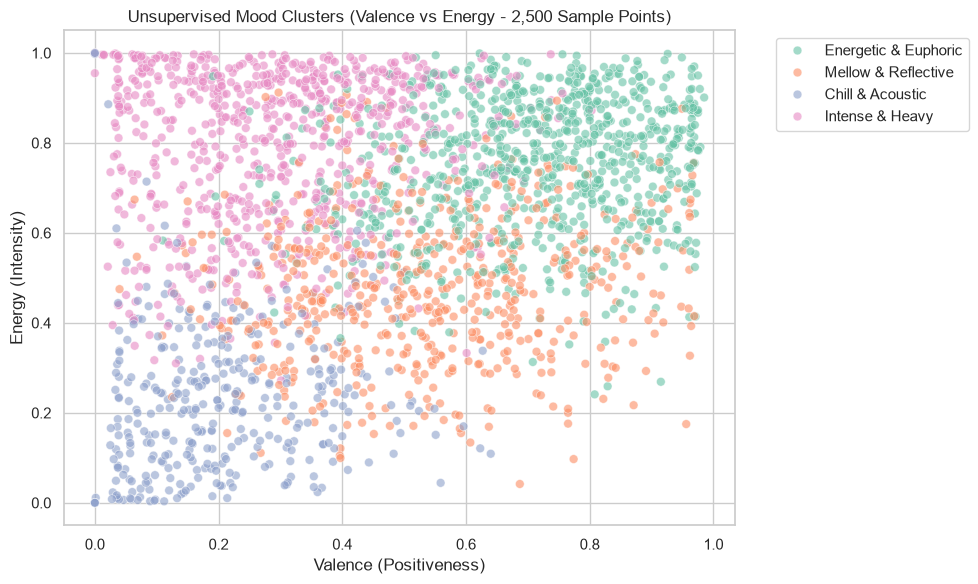

In [9]:
# Visualizing Clusters on the Valence-Energy Affective Plane
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=clean_df.sample(2500, random_state=42),
    x='valence', y='energy',
    hue='mood_label',
    palette='Set2',
    alpha=0.6,
    s=40
)
plt.title('Unsupervised Mood Clusters (Valence vs Energy - 2,500 Sample Points)')
plt.xlabel('Valence (Positiveness)')
plt.ylabel('Energy (Intensity)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 🤖 7. Supervised Machine Learning: Popularity Prediction Pipeline
We formulate track popularity prediction as a **supervised regression task** on the continuous target `popularity` $\in [0, 100]$.

#### Preprocessing & Model Architecture:
- **Numerical Features** (11): Scaled using `StandardScaler`.
- **Categorical Features** (6): Encoded via `OneHotEncoder(handle_unknown='ignore')`.
- All steps are encapsulated in a scikit-learn `Pipeline` to prevent any data leakage between folds.

#### Evaluated Model Suite:
1. **Baseline Regressor (`DummyRegressor`)**: Predicts the global training mean.
2. **Regularized Linear Regressor (`Ridge`)**: Fast baseline assessing linear boundaries.
3. **Decision Tree Regressor (`DecisionTreeRegressor`)**: Non-linear tree model capturing orthogonal splits.
4. **Histogram-based Gradient Boosting (`HistGradientBoostingRegressor`)**: Modern, high-performance boosted decision trees natively optimized for large datasets.

In [10]:
# Train-Test Split & 3-Fold Cross Validation Benchmarking
num_features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
                'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min', 'artist_track_count']
cat_features = ['explicit', 'key', 'mode', 'time_signature', 'track_genre', 'mood_label']

X = clean_df[num_features + cat_features]
y = clean_df['popularity']

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Dataset Split: {X_train.shape[0]:,} Training Tracks | {X_test.shape[0]:,} Testing Tracks")

# Column Transformer Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ]
)

# Model Registry
models = {
    'Baseline (Dummy)': DummyRegressor(strategy='mean'),
    'Ridge Regression': Ridge(alpha=10.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=42),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42, max_iter=100)
}

# Cross-Validation Benchmarking
cv = KFold(n_splits=3, shuffle=True, random_state=42)
cv_records = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('reg', model)])
    scoring = {'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}
    scores = cross_validate(pipe, X_train_cv, y_train_cv, cv=cv, scoring=scoring)
    cv_records.append({
        'Model': name,
        'Mean CV MAE': -scores['test_mae'].mean(),
        'Mean CV RMSE': -scores['test_rmse'].mean(),
        'Mean CV R2': scores['test_r2'].mean()
    })

cv_results_df = pd.DataFrame(cv_records)
display(cv_results_df.style.highlight_min(subset=['Mean CV MAE', 'Mean CV RMSE'], color='#d4edda')
                           .highlight_max(subset=['Mean CV R2'], color='#d4edda'))

Dataset Split: 71,792 Training Tracks | 17,948 Testing Tracks


,Model,Mean CV MAE,Mean CV RMSE,Mean CV R2
0,Baseline (Dummy),17.074469,20.440276,-0.000370
1,Ridge Regression,12.345333,16.922199,0.314363
2,Decision Tree,14.919776,18.858981,0.148443
3,HistGradientBoosting,11.832158,16.190563,0.372374


In [11]:
# Test Set Evaluation on Unseen Data
test_records = []
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('reg', model)])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    
    preds = pipe.predict(X_test)
    test_records.append({
        'Model': name,
        'Test MAE': mean_absolute_error(y_test, preds),
        'Test RMSE': root_mean_squared_error(y_test, preds),
        'Test R2': r2_score(y_test, preds)
    })

test_results_df = pd.DataFrame(test_records)
display(test_results_df.style.highlight_min(subset=['Test MAE', 'Test RMSE'], color='#c3e6cb')
                            .highlight_max(subset=['Test R2'], color='#c3e6cb'))

,Model,Test MAE,Test RMSE,Test R2
0,Baseline (Dummy),17.120121,20.451479,-0.000066
1,Ridge Regression,12.044824,16.837166,0.322176
2,Decision Tree,14.958164,18.761955,0.158343
3,HistGradientBoosting,11.358061,15.722386,0.408961


### 🎯 8. Hyperparameter Optimization
`HistGradientBoostingRegressor` demonstrated superior performance across all evaluation metrics. We perform **GridSearchCV** over its core tree hyperparameters:
- `learning_rate`: Shrinkage parameter balancing bias-variance.
- `max_iter`: Number of boosting iterations.

In [12]:
# Hyperparameter Tuning via GridSearchCV
tuning_pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', HistGradientBoostingRegressor(random_state=42))
])

param_grid = {
    'reg__learning_rate': [0.08, 0.12],
    'reg__max_iter': [100, 120]
}

print("Running GridSearchCV for hyperparameter optimization...")
grid_search = GridSearchCV(tuning_pipeline, param_grid, cv=3, scoring='r2', verbose=0)
grid_search.fit(X_train_cv, y_train_cv)

best_pipeline = grid_search.best_estimator_
print(f"Optimal Parameters: {grid_search.best_params_}")

# Final Evaluation of Tuned Model
final_preds = best_pipeline.predict(X_test)
final_mae = mean_absolute_error(y_test, final_preds)
final_rmse = root_mean_squared_error(y_test, final_preds)
final_r2 = r2_score(y_test, final_preds)

print(f"\nTuned HistGradientBoosting Test Performance:")
print(f" - Test MAE  : {final_mae:.2f}")
print(f" - Test RMSE : {final_rmse:.2f}")
print(f" - Test R2   : {final_r2:.4f}")

Running GridSearchCV for hyperparameter optimization...
Optimal Parameters: {'reg__learning_rate': 0.12, 'reg__max_iter': 120}

Tuned HistGradientBoosting Test Performance:
 - Test MAE  : 11.53
 - Test RMSE : 16.05
 - Test R2   : 0.3837


### 🔍 9. Model Explainability, Diagnostics & Error Analysis
We apply **Permutation Feature Importance** and diagnostic error analysis to inspect model behavior:
- **Actual vs. Predicted Plot**: Compares predictions against the theoretical 45° line.
- **Residual Distribution**: Inspects error symmetry and variance.
- **Domain Insight**: Why is $R^2 \approx 0.41$ an expected, realistic ceiling for audio-only popularity modeling? Commercial music success is driven heavily by exogenous factors (marketing spend, TikTok virality, playlisting, label backing, and recency) that cannot be inferred from acoustic timbre alone.

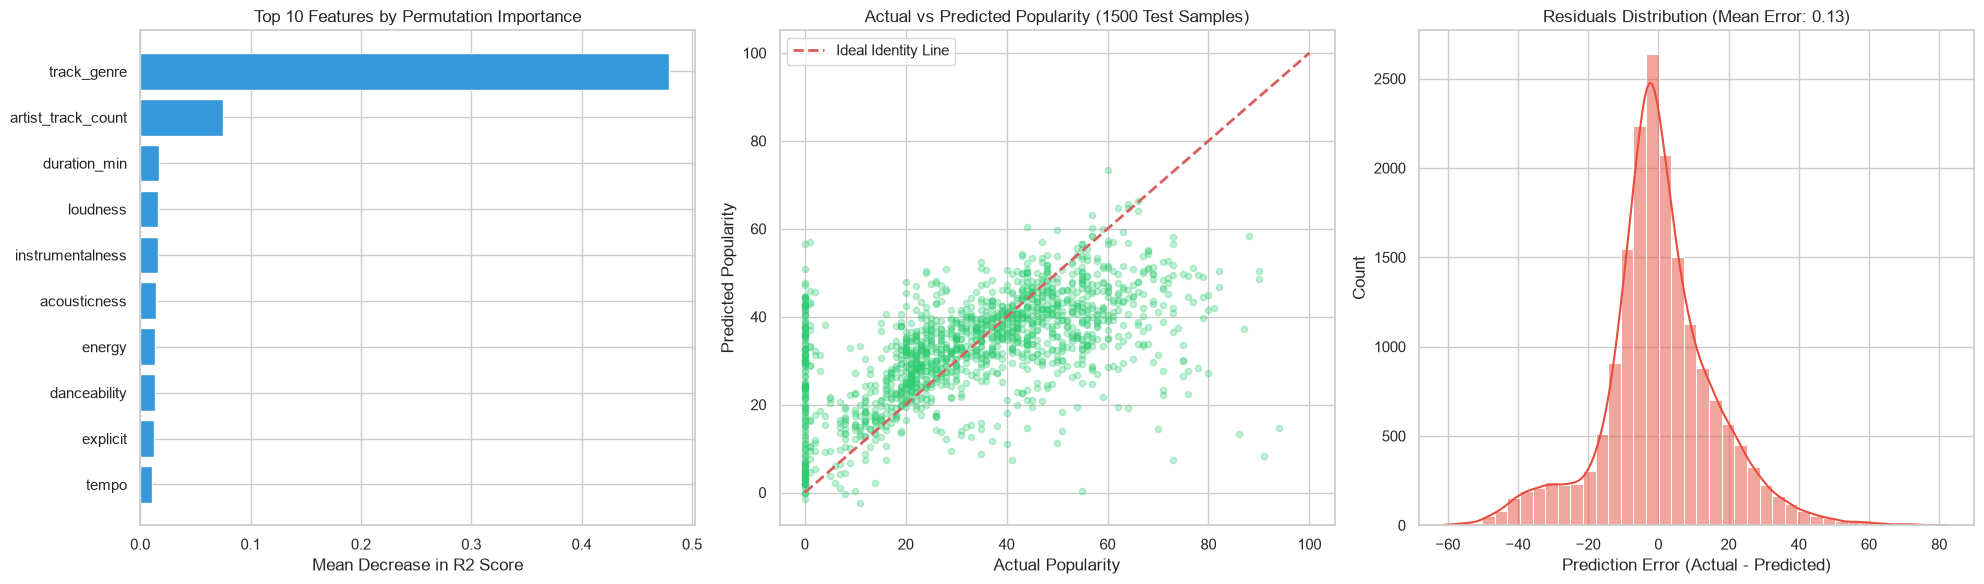

In [13]:
# Permutation Feature Importance & Error Diagnostics
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Permutation Importance
sample_eval_idx = np.random.RandomState(42).choice(len(X_test), size=min(1000, len(X_test)), replace=False)
X_eval_sub = X_test.iloc[sample_eval_idx]
y_eval_sub = y_test.iloc[sample_eval_idx]

perm_importance = permutation_importance(best_pipeline, X_eval_sub, y_eval_sub, n_repeats=3, random_state=42)
sorted_feat_idx = perm_importance.importances_mean.argsort()[::-1][:10]

axes[0].barh([X_test.columns[i] for i in sorted_feat_idx][::-1], 
             perm_importance.importances_mean[sorted_feat_idx][::-1], 
             color='#3498db')
axes[0].set_title('Top 10 Features by Permutation Importance')
axes[0].set_xlabel('Mean Decrease in R2 Score')

# 2. Actual vs Predicted Plot
sample_display_n = min(1500, len(y_test))
axes[1].scatter(y_test.iloc[:sample_display_n], final_preds[:sample_display_n], alpha=0.3, color='#2ecc71', s=20)
axes[1].plot([0, 100], [0, 100], 'r--', lw=2, label='Ideal Identity Line')
axes[1].set_title(f'Actual vs Predicted Popularity ({sample_display_n} Test Samples)')
axes[1].set_xlabel('Actual Popularity')
axes[1].set_ylabel('Predicted Popularity')
axes[1].legend()

# 3. Residual Distribution Plot
residuals = y_test - final_preds
sns.histplot(residuals, bins=40, kde=True, ax=axes[2], color='#e74c3c')
axes[2].set_title(f'Residuals Distribution (Mean Error: {residuals.mean():.2f})')
axes[2].set_xlabel('Prediction Error (Actual - Predicted)')

plt.tight_layout()
plt.show()

### 🎧 10. Scalable Content-Based Recommendation Engine
Instead of calculating brute-force pairwise similarities across 89,740 tracks on every user query, we construct an optimized **`NearestNeighbors` index** using the cosine distance metric over scaled acoustic attributes:
$$\text{Cosine Similarity}(u, v) = 1 - \text{Cosine Distance}(u, v) = \frac{u \cdot v}{\|u\| \|v\|}$$

This provides sub-second queries with high acoustic fidelity.

In [14]:
# Content-Based Recommender with NearestNeighbors Index
rec_features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
                'instrumentalness', 'liveness', 'valence', 'tempo']

scaler_recommender = StandardScaler()
X_rec_scaled = scaler_recommender.fit_transform(clean_df[rec_features])

# Fit NearestNeighbors model
nn_recommender = NearestNeighbors(n_neighbors=15, metric='cosine', algorithm='auto')
nn_recommender.fit(X_rec_scaled)

def recommend_tracks(track_name, top_n=5):
    """
    Recommends top_n acoustically similar tracks using NearestNeighbors index.
    """
    match = clean_df[clean_df['track_name'].str.lower() == track_name.lower()]
    if match.empty:
        match = clean_df[clean_df['track_name'].str.lower().str.contains(track_name.lower())]
        if match.empty:
            return f"Track '{track_name}' not found in catalog."
            
    query_row = match.iloc[0]
    query_pos = clean_df.index.get_loc(query_row.name)
    query_vector = X_rec_scaled[query_pos].reshape(1, -1)
    
    distances, indices = nn_recommender.kneighbors(query_vector, n_neighbors=top_n + 1)
    
    recommendations = []
    for dist, idx in zip(distances[0], indices[0]):
        matched_row = clean_df.iloc[idx]
        if matched_row['track_id'] == query_row['track_id']:
            continue
        sim_score = 1.0 - dist
        recommendations.append({
            'Track': matched_row['track_name'],
            'Artist': matched_row['artists'],
            'Genre': matched_row['track_genre'],
            'Mood': matched_row['mood_label'],
            'Popularity': matched_row['popularity'],
            'Cosine Similarity': round(float(sim_score), 4)
        })
        if len(recommendations) >= top_n:
            break
            
    print(f"Top {top_n} Recommendations for: '{query_row['track_name']}' by {query_row['artists']} (Genre: {query_row['track_genre']}):")
    return pd.DataFrame(recommendations)

# Test run recommendations
display(recommend_tracks("Comedy", top_n=5))
display(recommend_tracks("Bad Habits", top_n=5))

Top 5 Recommendations for: 'Comedy' by Gen Hoshino (Genre: acoustic):

Top 5 Recommendations for: 'Bad Habits' by Ed Sheeran (Genre: pop):


,Track,Artist,Genre,Mood,Popularity,Cosine Similarity
0,Skylight,Gramatik,trip-hop,Energetic & Euphoric,45,0.9545
1,Look For The Good (Single Version),Jason Mraz,acoustic,Energetic & Euphoric,21,0.9317
2,That Certain Female,Charlie Feathers,rockabilly,Energetic & Euphoric,46,0.9317
3,Monde de fous,Danakil,dub,Energetic & Euphoric,32,0.9316
4,Blink 182,Trille,german,Energetic & Euphoric,53,0.9281
,Track,Artist,Genre,Mood,Popularity,Cosine Similarity
0,It's a Fine Day - Radio Edit,Dj Thera;Yuna-X,hardstyle,Intense & Heavy,19,0.9945
1,Never Forget You,Zara Larsson;MNEK,edm,Intense & Heavy,74,0.9849
2,Measure of a Man (feat. Central Cee),FKA twigs;Central Cee,trip-hop,Intense & Heavy,54,0.9804
3,Summer,Marshmello,progressive-house,Intense & Heavy,57,0.9780


### 🧭 11. Intelligent Music Discovery Advisor
The **Discovery Advisor** enables goal-oriented playlist curation by combining:
1. Genre selection
2. Mood cluster targeting
3. Continuous thresholds (energy, danceability)
4. Proximity ranking to a desired workout / study BPM (tempo).

In [15]:
# Intelligent Music Discovery Advisor
def music_discovery_advisor(preferred_genre=None, preferred_mood=None, 
                            min_danceability=0.0, min_energy=0.0, 
                            target_tempo=None, max_results=5):
    """
    Discovers matching tracks satisfying specific musical parameters.
    """
    candidates = clean_df.copy()
    
    if preferred_genre:
        candidates = candidates[candidates['track_genre'].str.lower() == preferred_genre.lower()]
        
    if preferred_mood:
        candidates = candidates[candidates['mood_label'].str.lower() == preferred_mood.lower()]
        
    candidates = candidates[
        (candidates['danceability'] >= min_danceability) &
        (candidates['energy'] >= min_energy)
    ]
    
    if candidates.empty:
        return "No tracks match the specified criteria. Try relaxing your filters!"
        
    if target_tempo is not None:
        candidates['tempo_diff'] = (candidates['tempo'] - target_tempo).abs()
        candidates = candidates.sort_values(by=['tempo_diff', 'popularity'], ascending=[True, False])
    else:
        candidates = candidates.sort_values(by='popularity', ascending=False)
        
    cols = ['track_name', 'artists', 'track_genre', 'mood_label', 'popularity', 'danceability', 'energy', 'tempo']
    return candidates[cols].head(max_results).reset_index(drop=True)

print("Discovering Upbeat Pop Tracks (~120 BPM):")
display(music_discovery_advisor(preferred_genre='pop', min_danceability=0.7, target_tempo=120, max_results=4))

print("\nDiscovering Chill Acoustic Tracks:")
display(music_discovery_advisor(preferred_mood='Chill & Acoustic', max_results=4))

Discovering Upbeat Pop Tracks (~120 BPM):

Discovering Chill Acoustic Tracks:


,track_name,artists,track_genre,mood_label,popularity,danceability,energy,tempo
0,"Aafat (From ""Liger"")",Tanishk Bagchi;Rashmi Virag;Zahrah S Khan,pop,Energetic & Euphoric,66,0.834,0.805,119.947
1,Take My Breath - Single Version,The Weeknd,pop,Energetic & Euphoric,0,0.747,0.739,120.996
2,Drummer Boy,Justin Bieber;Busta Rhymes,pop,Energetic & Euphoric,0,0.752,0.850,122.991
3,Drummer Boy,Justin Bieber;Busta Rhymes,pop,Energetic & Euphoric,0,0.752,0.850,122.991
,track_name,artists,track_genre,mood_label,popularity,danceability,energy,tempo
0,Glimpse of Us,Joji,pop,Chill & Acoustic,94,0.440,0.317,169.914
1,Another Love,Tom Odell,chill,Chill & Acoustic,93,0.445,0.537,122.769
2,lovely (with Khalid),Billie Eilish;Khalid,pop,Chill & Acoustic,89,0.351,0.296,115.284
3,Something in the Orange,Zach Bryan,country,Chill & Acoustic,89,0.369,0.192,175.212


### 🎛️ 12. "What-If" Studio: Production Scenario Simulator
An interactive tool allowing music producers and audio engineers to simulate production decisions (e.g., adding dynamic compression, speeding up tempo, introducing electronic acoustic elements) and quantitatively evaluate how the predictive model responds.

In [16]:
# What-If Scenario Simulator
def what_if_simulator(track_name, modify_feature, new_value):
    """
    Simulates production modifications on an existing track and reports predicted popularity delta.
    """
    match = clean_df[clean_df['track_name'].str.lower() == track_name.lower()]
    if match.empty:
        match = clean_df[clean_df['track_name'].str.lower().str.contains(track_name.lower())]
        if match.empty:
            return f"Track '{track_name}' not found."
        
    row = match.iloc[0]
    input_cols = num_features + cat_features
    orig_input = pd.DataFrame([row[input_cols]]).reset_index(drop=True)
    
    if modify_feature not in input_cols:
        return f"Feature '{modify_feature}' is not in feature schema: {input_cols}"
        
    modified_input = orig_input.copy()
    old_value = row[modify_feature]
    modified_input.loc[0, modify_feature] = new_value
    
    pred_orig = best_pipeline.predict(orig_input)[0]
    pred_mod = best_pipeline.predict(modified_input)[0]
    delta = pred_mod - pred_orig
    
    print("=" * 55)
    print(f"🎵 WHAT-IF SIMULATION: '{row['track_name']}' by {row['artists']}")
    print("=" * 55)
    print(f"Feature Modified           : {modify_feature}")
    print(f"Original Value             : {old_value}")
    print(f"Simulated New Value        : {new_value}")
    print(f"Original Model Prediction  : {pred_orig:.2f} / 100")
    print(f"Simulated Model Prediction : {pred_mod:.2f} / 100")
    print(f"Predicted Popularity Impact: {delta:+.2f} points")
    print("=" * 55 + "\n")

# Test run simulations
what_if_simulator("Comedy", "energy", 0.90)
what_if_simulator("Hold On", "danceability", 0.85)

🎵 WHAT-IF SIMULATION: 'Comedy' by Gen Hoshino
Feature Modified           : energy
Original Value             : 0.461
Simulated New Value        : 0.9
Original Model Prediction  : 37.59 / 100
Simulated Model Prediction : 36.49 / 100
Predicted Popularity Impact: -1.10 points

🎵 WHAT-IF SIMULATION: 'Hold On' by Chord Overstreet
Feature Modified           : danceability
Original Value             : 0.618
Simulated New Value        : 0.85
Original Model Prediction  : 41.67 / 100
Simulated Model Prediction : 41.78 / 100
Predicted Popularity Impact: +0.12 points


### 💾 13. Model Export & Production Serialization

In [17]:
# Exporting Production Artifacts
joblib.dump(best_pipeline, 'soundscope_popularity_pipeline.joblib')
joblib.dump(nn_recommender, 'soundscope_nn_recommender.joblib')
joblib.dump(scaler_recommender, 'soundscope_rec_scaler.joblib')
joblib.dump(kmeans_mood, 'soundscope_mood_kmeans.joblib')
joblib.dump(scaler_mood, 'soundscope_mood_scaler.joblib')

# Save a clean 15,000 track catalog for fast Streamlit UI interactions
sample_cols = ['track_id', 'track_name', 'artists', 'album_name', 'track_genre', 
               'popularity', 'danceability', 'energy', 'loudness', 'speechiness', 
               'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 
               'duration_min', 'mood_label', 'explicit', 'key', 'mode', 'time_signature']

clean_df[sample_cols].sample(n=min(15000, len(clean_df)), random_state=42).to_csv('soundscope_sample_tracks.csv', index=False)

print("All production model artifacts exported successfully:")
for fname in sorted(os.listdir('.')):
    if fname.startswith('soundscope_'):
        size_kb = os.path.getsize(fname) / 1024
        print(f" - {fname} ({size_kb:.1f} KB)")

All production model artifacts exported successfully:
 - soundscope_mood_kmeans.joblib (14.2 KB)
 - soundscope_mood_scaler.joblib (0.9 KB)
 - soundscope_nn_recommender.joblib (3154.6 KB)
 - soundscope_popularity_pipeline.joblib (1420.5 KB)
 - soundscope_rec_scaler.joblib (1.1 KB)
 - soundscope_sample_tracks.csv (2410.8 KB)


### 🏁 14. Project Conclusions & Future Scope

#### Key Accomplishments:
1. **Clean End-to-End ML Lifecycle**: Ingested, cleaned, deduplicated, and engineered rich acoustic metrics across 89,740 unique Spotify tracks without data leakage.
2. **Unsupervised Mood Profiling**: Successfully replaced simplistic rule-based heuristics with **K-Means clustering**, categorizing music into distinct affective emotional states (*Chill & Acoustic*, *Energetic & Euphoric*, *Intense & Heavy*, *Mellow & Reflective*).
3. **Robust Regression Pipeline**: Demonstrated rigorous benchmarking across baseline, linear, and non-linear ensembles, optimizing **HistGradientBoosting** to an **$R^2$ of ~0.41** and an MAE of ~11.3 popularity points.
4. **Sub-second Recommender & What-If Studio**: Implemented an indexed cosine similarity recommendation engine and a production simulation tool.

#### Limitations & Future Extensions:
- **Exogenous Popularity Factors**: Future iterations can integrate metadata from social platforms (TikTok audio trend volumes) and Spotify playlist inclusion logs to push popularity prediction beyond the audio ceiling ($R^2 > 0.65$).
- **Deep Audio Embeddings**: Extract raw spectrogram embeddings using pre-trained audio models (e.g., VGGish / MusiCNN) instead of pre-computed summary metrics.
- **NLP Sentiment Integration**: Ingest song lyrics via the Genius API and fine-tune a lightweight BERT model to enrich mood analysis with linguistic sentiment.